# KM survival and finite-horizon analysis — `zedstat` API

This notebook configures **the ILD analysis** and invokes the reusable survival API in the **installed `zedstat` package**. No statistics, fitting, plotting, or LaTeX implementation code is embedded here.

The original analysis settings are retained: 97.5%-specificity code `0975`, maximum plotted week 24, original KM duration prefilter, unchanged colors/styles, and the existing input and output filenames. The `original_filter` option preserves the historical results but is not a recommended prospective risk-set construction.

In [1]:
from pathlib import Path
import pandas as pd
from zedstat import survival

# Confirm the installed zedstat exposes the package API required below.
# This is an installation check, not a statistical or plotting implementation.
_REQUIRED_SURVIVAL_API = (
    "plot_km_comparison",
    "plot_finite_horizon_comparison",
    "export_survival_summary_table",
)
_missing = [name for name in _REQUIRED_SURVIVAL_API if not callable(getattr(survival, name, None))]
print("Imported zedstat.survival:", survival.__file__)
if _missing:
    raise ImportError(
        "Installed zedstat.survival is outdated; missing: "
        + ", ".join(_missing)
        + ". Update the zedstat source and run: "
        + "%pip install --no-deps --force-reinstall --no-cache-dir "
        + "/home/ishanu/Dropbox/ZED/Research/zedstat; "
        + "then restart the kernel."
    )


# Analysis-specific configuration (not part of the general-purpose package)
TAG = '50'
SPEC_CODE = '0975'
MAX_WEEK = 24
LANDMARK_WEEKS = (1, 2, 4, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26)
COHORT_DIRS = {
    'MarketScan': Path('PAPER_DATA_MARKETSCAN/survival_MARKETSCAN'),
    'UKHC': Path(f'PAPER_DATA_UKHC_{TAG}TRAINING/survival_UKHC'),
}
MODELS = {
    'ILD-AFSTDPULMO': 'Pulmonary_Hypertension',
    'ILD-AFSTDOXYGEN': 'Oxygen_Dependence',
    'ILD-AFSTDARDS': 'ARDS',
}
OUTPUT_DIR = Path('PUBLICATION_FILES/survival_JOINED')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

COHORT_PLOT_ORDER = ('UKHC', 'MarketScan')
COHORT_TABLE_ORDER = ('MarketScan', 'UKHC')
COHORT_STYLES = {'MarketScan': '-', 'UKHC': '--'}
KM_GROUP_COLORS = {1: '#569D3E', 0: '#BE3D30'}
METRIC_COLORS = {
    'P_event_within_k_given_crossed': '#4675AF',
    'P_no_event_within_k_given_never_crossed': '#E88833',
    'P_crossed_given_event_within_k': '#569D3E',
    'P_never_crossed_given_no_event_within_k': '#BE3D30',
}
print('zedstat survival module:', survival.__file__)

Imported zedstat.survival: /home/ishanu/Dropbox/ZED/Research/zedstat/zedstat/survival.py
zedstat survival module: /home/ishanu/Dropbox/ZED/Research/zedstat/zedstat/survival.py


## Load saved patient-level results and horizon metrics

In [2]:
patients = {model: {} for model in MODELS}
horizon_metrics = {model: {} for model in MODELS}
summaries = []

for cohort, directory in COHORT_DIRS.items():
    saved = pd.read_csv(directory / 'SUMMARY.csv', dtype={'SPEC': str})
    selection = (
        saved['SPEC'].str.zfill(len(SPEC_CODE)).eq(SPEC_CODE)
        & saved['M'].isin(MODELS.values())
        & saved['week'].eq(MAX_WEEK)
    )
    summaries.append(saved.loc[selection].assign(source=cohort).copy())
    for model in MODELS:
        patients[model][cohort] = pd.read_csv(
            directory / f'km_full_cohort_{model}_{SPEC_CODE}.csv'
        )
        horizon_metrics[model][cohort] = pd.read_csv(
            directory / f'dynamic_metrics_full_cohort_{model}_{SPEC_CODE}.csv'
        )

summary_df = pd.concat(summaries, ignore_index=True)
summary_df.to_csv(OUTPUT_DIR / 'SUMMARY.csv', index=False)
display(summary_df)

,M,SPEC,threshold_type,specificity,retrospective_specificity,threshold,n_total,n_crossed,n_never_crossed,events_crossed,...,event_only_dynamic_FP_k,event_only_dynamic_FN_k,event_only_dynamic_TN_k,event_only_dynamic_P_event_within_k_given_crossed,event_only_dynamic_P_no_event_within_k_given_never_crossed,event_only_dynamic_P_crossed_given_event_within_k,event_only_dynamic_P_never_crossed_given_no_event_within_k,event_only_dynamic_dynamic_LR_plus,event_only_dynamic_dynamic_LR_minus,source
0,Pulmonary_Hypertension,0975,Stricter threshold,0.975,0.975,0.207516,18241,1416.0,16825.0,880,...,483.0,436.0,759.0,0.451136,0.635146,0.476591,0.611111,1.225519,0.856488,MarketScan
1,Oxygen_Dependence,0975,Stricter threshold,0.975,0.975,0.162497,17975,1298.0,16677.0,745,...,376.0,248.0,428.0,0.495302,0.633136,0.598055,0.532338,1.278820,0.755055,MarketScan
2,ARDS,0975,Stricter threshold,0.975,0.975,0.399771,18738,2469.0,16269.0,1933,...,974.0,1156.0,1901.0,0.496120,0.621851,0.453428,0.661217,1.338404,0.826615,MarketScan
3,Pulmonary_Hypertension,0975,Stricter threshold,0.975,0.975,0.718845,1206,129.0,1077.0,83,...,36.0,89.0,136.0,0.566265,0.604444,0.345588,0.790698,1.651144,0.827638,UKHC
4,Oxygen_Dependence,0975,Stricter threshold,0.975,0.975,0.805907,1251,166.0,1085.0,132,...,41.0,128.0,196.0,0.689394,0.604938,0.415525,0.827004,2.401938,0.706737,UKHC
5,ARDS,0975,Stricter threshold,0.975,0.975,0.746289,1215,220.0,995.0,191,...,77.0,150.0,239.0,0.596859,0.614396,0.431818,0.756329,1.772137,0.751236,UKHC


## Reproduce the two original figure families

ILD-AFSTDPULMO


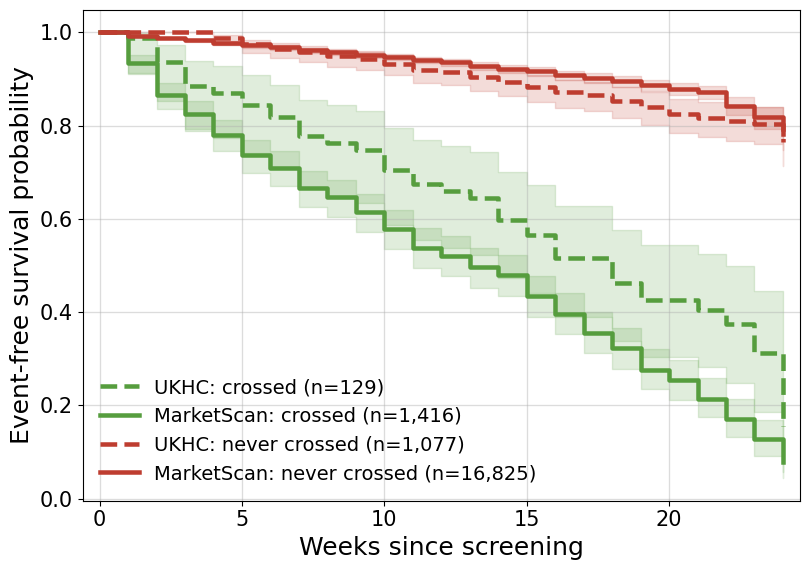

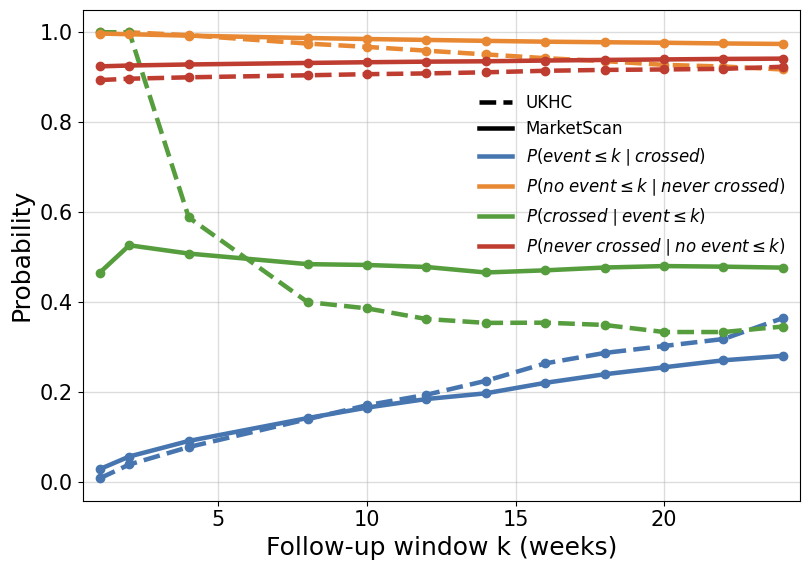

ILD-AFSTDOXYGEN


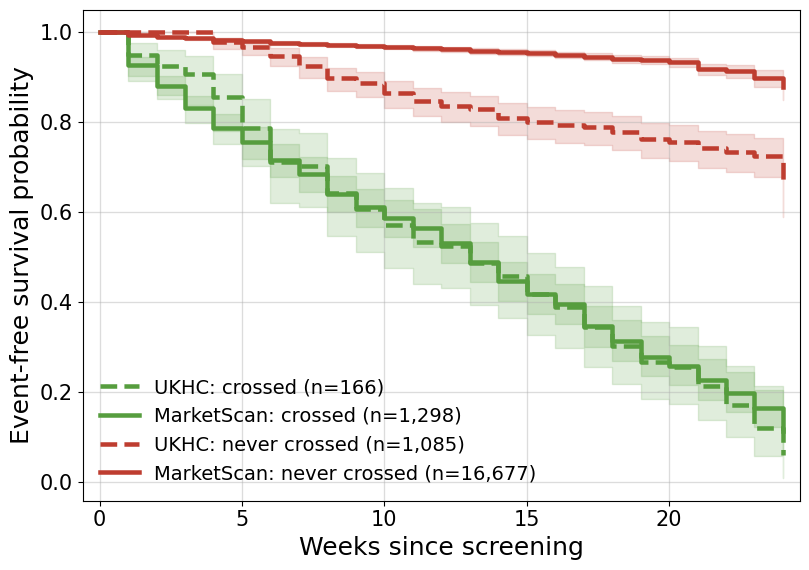

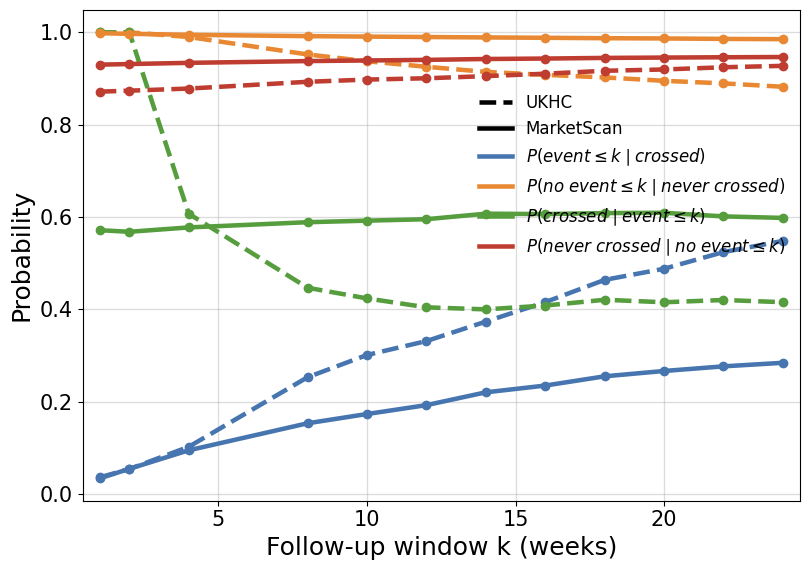

ILD-AFSTDARDS


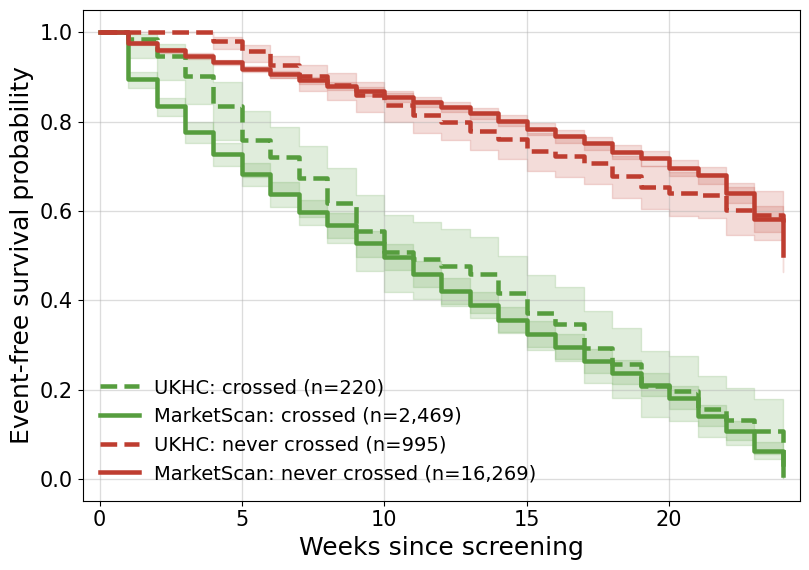

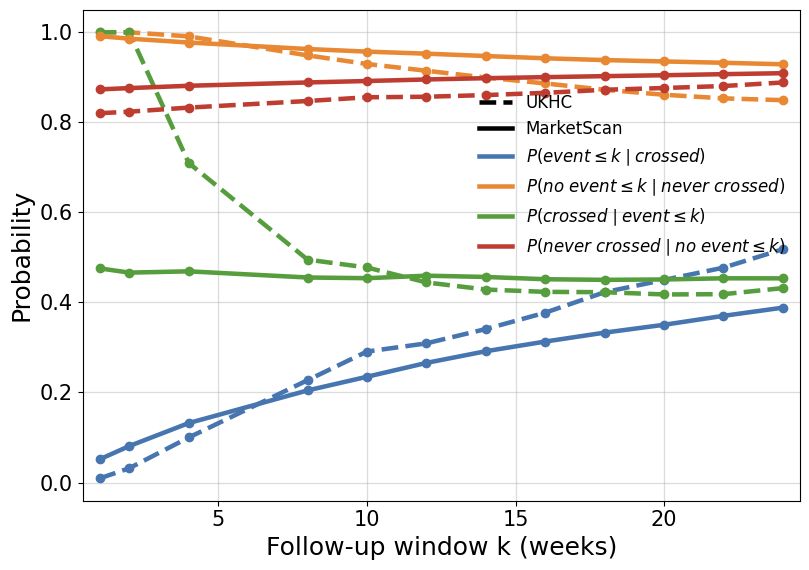

In [3]:
for model in MODELS:
    print(model)
    survival.plot_km_comparison(
        patients[model], cohort_order=COHORT_PLOT_ORDER,
        cohort_linestyles=COHORT_STYLES, group_colors=KM_GROUP_COLORS,
        max_week=MAX_WEEK, risk_set_mode='original_filter',
        ci_show=True, ci_alpha=0.18, linewidth=3.25,
        legend_fontsize=14, dpi=600,
        outfile=OUTPUT_DIR / f'km_{model}.png', show=True, close=True,
    )
    survival.plot_finite_horizon_comparison(
        horizon_metrics[model], cohort_order=COHORT_PLOT_ORDER,
        cohort_linestyles=COHORT_STYLES, metric_colors=METRIC_COLORS,
        max_week=MAX_WEEK, landmark_weeks=LANDMARK_WEEKS,
        linewidth=3.25, marker_size=6, dpi=600,
        outfile=OUTPUT_DIR / f'dynamic_metrics_{model}.png',
        show=True, close=True,
    )

## Export the original 24-week summary table

In [4]:
latex_path = survival.export_survival_summary_table(
    summary_df, OUTPUT_DIR / 'KM_SUMMARY_TABLE.tex',
    horizon=MAX_WEEK, specificity=SPEC_CODE,
    targets=tuple(MODELS.values()), cohorts=COHORT_TABLE_ORDER,
)
print(latex_path)
print(latex_path.read_text(encoding='utf-8'))

PUBLICATION_FILES/survival_JOINED/KM_SUMMARY_TABLE.tex
\begin{table}[ht!]
\centering
\caption{Threshold-based event enrichment in MarketScan and UKHC at 24 weeks using the 97.5\%-specificity operating point}
\label{table_SURVIVAL}
\normalfont\fontsize{11}{13}\selectfont

\resizebox{\textwidth}{!}{%
% Reduce horizontal padding to allow larger text within the page width.
\setlength{\tabcolsep}{3pt}%
% Local vertical padding for this table only.
\renewcommand{\arraystretch}{1.25}%
\setlength{\extrarowheight}{2pt}%
\begin{tabular}{L{0.95in}lrrrrrrrr}
\hline
\raisebox{-0.5\height}{\textbf{Event}} &
\raisebox{-0.5\height}{\textbf{Source}} &
\raisebox{-0.5\height}{\textbf{\shortstack{Risk\\threshold}}} &
\raisebox{-0.5\height}{\textbf{\shortstack{Crossed\\/ total}}} &
\raisebox{-0.5\height}{\textbf{\shortstack{Crossing\\rate}}} &
\raisebox{-0.5\height}{\textbf{\shortstack{Event probability\\if crossed}}} &
\raisebox{-0.5\height}{\textbf{\shortstack{Event probability\\if never crossed}}} &
\ra